# Human tonsil

Integrate multimodal inputs with MELON, identify spatial domains, and visualize the tissue.

The functions show the computation at each stage. The following cells continue from the supplied intermediate files, so training and clustering are not repeated. Start with prepared modality features; see the [Tutorials](https://txbrook.github.io/MELON_website/tutorials/) for preprocessing.

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
from _shared.workflow import assay_shape, align_partition
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "04_Human_tonsil"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

## 1. Assemble the multimodal inputs

RNA, protein and 2,048-dimensional image features share 4,194 spatial barcodes. Image features have already been extracted with InceptionV3. These files are the inputs to the normalization and integration workflow.

In [2]:
input_paths = {'RNA': '02_model_inputs/MELON/adata_RNA.h5ad', 'Protein': '02_model_inputs/MELON/adata_protein.h5ad', 'Image': '02_model_inputs/MELON/adata_image.h5ad'}
input_paths = {name: DATA / path for name, path in input_paths.items()}
coords = read_indexed(DATA / "01_source_data/coords.csv")[["x", "y"]]
input_shapes = {name: assay_shape(path) for name, path in input_paths.items()}
assert all(shape[0] == len(coords) for shape in input_shapes.values())
display(input_shapes)

{'RNA': (4194, 18030), 'Protein': (4194, 35), 'Image': (4194, 2048)}

## 2. Configure and train MELON

The model combines modality-specific encoders with spatial attention and contrastive representation learning. The result node uses 30 epochs, batch size 4,096, spatial k = 6 and seed 42; these values come from its run metadata. That run used an algebraically equivalent memory-efficient InfoNCE implementation. The repository runner also provides the manuscript-default configuration.

Model construction and embedding export use the [MELON implementation](../_shared/engine.py). `integrate_modalities` takes prepared feature arrays in the modality order above, together with their aligned coordinates.

Edit the configuration cell below to adjust the model parameters.

In [3]:
# Edit the parameters here.
config = {
    'epochs': 30,
    'batch_size': 4096,
    'embed_dim': 128,
    'training_seed': 42,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 6,
    'export_spatial_k': None,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'historical_five_modal': False,
    'clustering_seed': 2025,
    'target_clusters': 10,
    'kmeans_n_init': 20,
}

In [4]:
def integrate_modalities(features, coordinates, config):
    """Learn a joint representation from aligned, preprocessed modality arrays."""
    import torch
    import pytorch_lightning as pl
    from _shared.engine import make_model, export_embedding, PaperAugmentations
    from _shared.publication_model.data import DualAugDataModule, SpatialOmicsAugmentations
    from _shared.publication_model.utils import build_knn_mask

    pl.seed_everything(config["training_seed"], workers=True)
    tensors = [torch.as_tensor(x, dtype=torch.float32) for x in features]
    xy = torch.as_tensor(coordinates.to_numpy(), dtype=torch.float32)
    mask, weight = build_knn_mask(xy, k=config["training_spatial_k"],
                                  include_self=True, return_weights=True)
    augmentation = SpatialOmicsAugmentations if config["historical_five_modal"] else PaperAugmentations
    aug = dict(augmentations=config.get("augmentations", ["gaussian_noise", "feature_dropout", "neighbor_mix"]),
               p=config["augment_p"])
    data = DualAugDataModule(
        mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weight,
        batch_size=config["batch_size"], augmentA=augmentation(**aug), augmentB=augmentation(**aug),
        spot_tokenization=True, shuffle=config["shuffle_batches"])
    model = make_model([x.shape[1] for x in features], config)
    trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                         logger=False, enable_checkpointing=False, deterministic=True)
    trainer.fit(model, datamodule=data)
    z = export_embedding(model, tensors, xy, config["export_spatial_k"])
    return pd.DataFrame(z, index=coordinates.index)

The output of this stage is one joint embedding vector per spatial barcode. Continue from that intermediate representation below.

In [5]:
# Continue at the joint-representation node produced by MELON.
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
embedding = align_embedding(embedding, coords)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})

{'spots': 4194, 'embedding_dimensions': 128}

## 3. Identify spatial domains

Apply k-means to the native 128-dimensional MELON embedding with 10 clusters and 20 initializations. The partition node supplies the domain assignments for the next step.

In [6]:
def identify_domains(embedding):
    from sklearn.cluster import KMeans
    labels = KMeans(n_clusters=config["target_clusters"], n_init=config["kmeans_n_init"], random_state=config["clustering_seed"]).fit_predict(embedding)
    return pd.Series(labels, index=embedding.index, name="MELON")

domains = align_partition(DATA / "04_clusters/final_clusters.csv", embedding)
display({"spatial_domains": domains.nunique()})

{'spatial_domains': 10}

## 4. Map domains onto the tissue

Join domain assignments to spatial coordinates by barcode. Each point represents one spot.

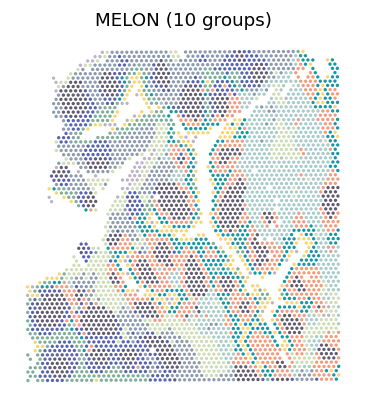

In [7]:
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON"] = domains
colors = tonsil_colors(DATA)
show(spatial_panels(plot_data, ["MELON"], colors=colors, ncols=1))